# 06 — Suivi des expériences avec MLflow

Toutes les évaluations du dossier `results/` sont enregistrées dans MLflow (paramètres, métriques par type de question, réponses en artefacts). Ce notebook interroge MLflow pour analyser deux séries d'expériences menées sur le jeu **dev** :

1. une **grille sur le RAG simple** : taille des chunks (256, 512, 1024 tokens) et nombre de passages retrouvés (3, 5, 8) ;
2. une **étude d'ablation des agents** : vérificateur avec le modèle 4B, sans vérificateur, et vérificateur avec un modèle plus grand (`qwen3:8b`).

Ces nouvelles évaluations sont notées par le LLM-juge seulement, sans relecture humaine. Le juge étant en accord avec la relecture dans environ 80 % des cas, un écart d'exactitude inférieur à 0,05 (deux questions sur 40) ne peut pas être interprété.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import matplotlib.pyplot as plt
import mlflow
import pandas as pd

from assistant_rag.config import RESULTS_DIR
from assistant_rag.evaluation.runner import load_records
from assistant_rag.tracking import CONFIG_FILE, log_results_dir, setup_experiment

pd.set_option("display.precision", 3)

for run_dir in sorted(path for path in RESULTS_DIR.iterdir() if (path / CONFIG_FILE).exists()):
    log_results_dir(run_dir)

runs = mlflow.search_runs([setup_experiment()]).set_index("tags.results_dir").sort_index()
print(f"{len(runs)} évaluations enregistrées dans MLflow")

13 évaluations enregistrées dans MLflow


In [3]:
METRICS = {
    "metrics.multi_articles.retrieval_recall": "rappel@k multi-articles",
    "metrics.ensemble.citation_precision": "précision des citations",
    "metrics.factuelle.correctness": "exactitude factuelles",
    "metrics.multi_articles.correctness": "exactitude multi-articles",
    "metrics.ensemble.correctness": "exactitude ensemble",
    "metrics.ensemble.latency": "latence (s)",
    "metrics.ensemble.llm_calls": "appels au LLM",
}


def table(run_names, params):
    columns = {f"params.settings.{name}": name for name in params}
    return runs.loc[run_names, list(columns) + list(METRICS)].rename(columns={**columns, **METRICS})

## 1. Grille sur le RAG simple

### Taille des chunks (k = 5)

In [4]:
chunk_runs = ["simple-c256-dev", "simple-v2-dev", "simple-c1024-dev"]
table(chunk_runs, ["chunk_size", "chunk_overlap", "top_k"])

,chunk_size,chunk_overlap,top_k,rappel@k multi-articles,précision des citations,exactitude factuelles,exactitude multi-articles,exactitude ensemble,latence (s),appels au LLM
tags.results_dir,,,,,,,,,,
simple-c256-dev,256,32,5,0.875,0.964,0.875,0.688,0.828,5.285,1.0
simple-v2-dev,512,64,5,0.812,0.922,0.896,0.688,0.844,6.345,1.0
simple-c1024-dev,1024,128,5,0.875,0.982,0.917,0.875,0.906,5.983,1.0


### Nombre de passages retrouvés (chunks de 512 tokens)

In [5]:
k_runs = ["simple-k3-dev", "simple-v2-dev", "simple-k8-dev"]
table(k_runs, ["chunk_size", "top_k"])

,chunk_size,top_k,rappel@k multi-articles,précision des citations,exactitude factuelles,exactitude multi-articles,exactitude ensemble,latence (s),appels au LLM
tags.results_dir,,,,,,,,,
simple-k3-dev,512,3,0.812,0.943,0.917,0.688,0.859,3.857,1.0
simple-v2-dev,512,5,0.812,0.922,0.896,0.688,0.844,6.345,1.0
simple-k8-dev,512,8,0.938,0.930,0.917,0.812,0.891,6.453,1.0


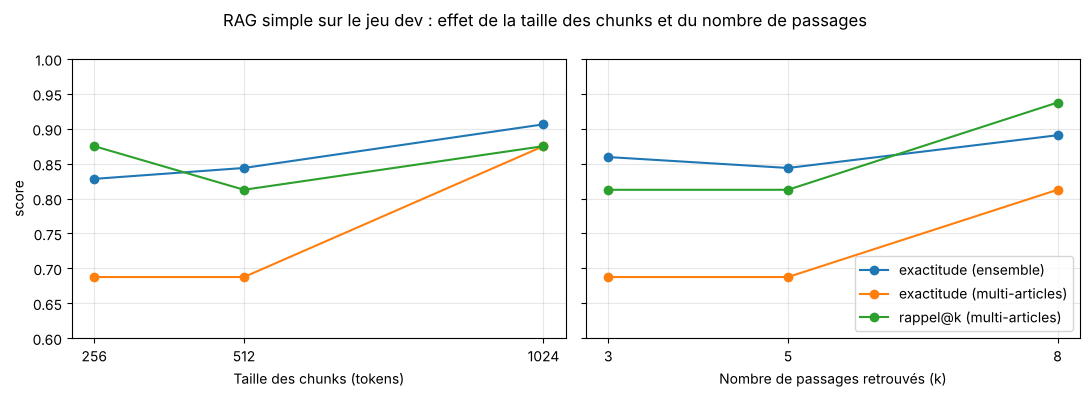

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
series = {
    "metrics.ensemble.correctness": "exactitude (ensemble)",
    "metrics.multi_articles.correctness": "exactitude (multi-articles)",
    "metrics.multi_articles.retrieval_recall": "rappel@k (multi-articles)",
}
for ax, run_names, parameter, label in [
    (axes[0], chunk_runs, "params.settings.chunk_size", "Taille des chunks (tokens)"),
    (axes[1], k_runs, "params.settings.top_k", "Nombre de passages retrouvés (k)"),
]:
    x = runs.loc[run_names, parameter].astype(int)
    for metric, name in series.items():
        ax.plot(x, runs.loc[run_names, metric], marker="o", label=name)
    ax.set_xticks(x)
    ax.set_xlabel(label)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("score")
axes[0].set_ylim(0.6, 1.0)
axes[1].legend(loc="lower right")
fig.suptitle("RAG simple sur le jeu dev : effet de la taille des chunks et du nombre de passages")
plt.tight_layout()
plt.show()

Les chunks de 1024 tokens et k = 8 donnent les meilleurs résultats : avec plus de texte par question, les questions multi-articles retrouvent plus souvent leurs deux articles. Les chunks de 1024 tokens obtiennent la meilleure exactitude (0,91) et la meilleure précision des citations (0,98), sans coût de latence. Les écarts restent toutefois de l'ordre de deux à trois questions sur 40.

## 2. Ablation des agents

In [7]:
agent_runs = {
    "agents-v2-dev": "vérificateur 4B",
    "agents-sans-verif-dev": "sans vérificateur",
    "agents-verif8b-dev": "vérificateur 8B",
}
ablation = table(list(agent_runs), []).rename(index=agent_runs)
ablation

,rappel@k multi-articles,précision des citations,exactitude factuelles,exactitude multi-articles,exactitude ensemble,latence (s),appels au LLM
tags.results_dir,,,,,,,
vérificateur 4B,0.938,0.943,0.875,0.750,0.844,11.521,3.3
sans vérificateur,0.938,0.943,0.875,0.750,0.844,5.925,2.0
vérificateur 8B,0.938,0.953,0.854,0.812,0.844,17.003,3.6


In [8]:
def verifier_behaviour(run):
    records = [r for r in load_records(RESULTS_DIR / run / "answers.jsonl") if r["type"] != "hors_corpus"]
    corrected = converged = 0
    scores = {True: [], False: []}
    for record in records:
        verdicts = [step["verdict"] for step in record["trace"] if step["agent"] == "vérificateur"]
        if len(verdicts) > 1:
            corrected += 1
            converged += verdicts[-1] == "valide"
        if record["verified"] is not None and record["judge"]:
            scores[record["verified"]].append(record["judge"]["score"])
    return {
        "réponses corrigées": corrected,
        "corrections validées": converged,
        "réponses non validées": len(scores[False]),
        "exactitude des réponses validées": sum(scores[True]) / len(scores[True]),
        "exactitude des réponses non validées": sum(scores[False]) / len(scores[False]),
    }


pd.DataFrame({agent_runs[run]: verifier_behaviour(run) for run in ["agents-v2-dev", "agents-verif8b-dev"]})

,vérificateur 4B,vérificateur 8B
réponses corrigées,5.00,9.000
corrections validées,0.00,3.000
réponses non validées,5.00,6.000
exactitude des réponses validées,0.87,0.923
exactitude des réponses non validées,0.70,0.500


- **Sans vérificateur**, l'exactitude est identique (0,84) et le temps de réponse est divisé par deux : avec le modèle 4B, le vérificateur ne change pas la qualité des réponses.
- **Avec un vérificateur 8B**, l'exactitude reste la même, mais le vérificateur devient plus utile : 3 corrections sur 9 aboutissent à une réponse validée (aucune avec le modèle 4B), et l'écart d'exactitude entre réponses validées et non validées se creuse (0,92 contre 0,50). Il distingue donc mieux les réponses douteuses, au prix d'une latence multipliée par 1,5 et d'un modèle qui ne tient pas dans les 8 Go de RAM du poste de développement.

## 3. Choix

| Question | Choix | Justification |
| --- | --- | --- |
| Configuration du RAG simple | chunks de 1024 tokens, k = 5 | meilleure exactitude et meilleure précision des citations sur le jeu dev, même latence |
| Vérificateur du mode agents | conservé avec le modèle 4B | même exactitude, mais il signale les réponses douteuses ; le modèle 8B est plus fiable mais trop lourd pour le poste local |

La configuration retenue pour le RAG simple a été choisie parmi six sur le jeu dev. Son avantage peut donc être en partie dû au hasard : elle doit être confirmée **une seule fois** sur le jeu test avant de remplacer la configuration actuelle.

## 4. Confirmation sur le jeu test

La configuration « chunks de 1024 tokens » a été évaluée une seule fois sur le jeu test, puis ses 16 réponses notées ont été relues à la main, comme pour la configuration actuelle.

In [9]:
def reviewed(run):
    records = [r for r in load_records(RESULTS_DIR / run / "answers.jsonl") if r["type"] != "hors_corpus"]
    review = pd.read_csv(RESULTS_DIR / run / "revue_humaine.csv").set_index("id")
    scores = review["verdict_humain"].map({"correct": 1.0, "partiel": 0.5, "incorrect": 0.0})
    types = pd.Series({r["id"]: r["type"] for r in records})
    by_type = scores.groupby(types).mean()
    by_type["ensemble"] = scores.mean()
    return by_type


confirmation = pd.DataFrame(
    {"chunks de 512 (actuel)": reviewed("simple-test"), "chunks de 1024": reviewed("simple-c1024-test")}
)
confirmation.loc["latence moyenne (s)"] = [
    runs.loc["simple-test", "metrics.ensemble.latency"],
    runs.loc["simple-c1024-test", "metrics.ensemble.latency"],
]
confirmation

,chunks de 512 (actuel),chunks de 1024
factuelle,0.958,0.917
multi_articles,0.875,1.000
ensemble,0.938,0.938
latence moyenne (s),7.395,9.144


L'avantage observé sur le jeu dev **ne se confirme pas** : sur le jeu test, les deux configurations obtiennent la même exactitude relue (0,94). Les chunks de 1024 tokens répondent mieux aux questions multi-articles, mais moins bien à une question factuelle où le rédacteur se contredit sur deux délais.

**Décision.** La configuration actuelle (chunks de 512 tokens, k = 5) est conservée : à exactitude égale, elle demande une fenêtre de contexte plus petite (6 144 tokens au lieu de 8 192), donc moins de mémoire et un temps de réponse plus court sur le poste local. Les chunks de 1024 tokens restent disponibles par variables d'environnement (`CHUNK_SIZE`, `CHUNK_OVERLAP`, `CONTEXT_WINDOW`).

Cet exemple illustre l'intérêt de séparer les jeux dev et test : la meilleure des six configurations sur le jeu dev doit en partie son avance au hasard de la sélection.